# Lab 06: Landmark Recognition & Localization Using SIFT
Implementation of SIFT feature extraction, BFMatcher with Lowe's ratio test, RANSAC homography localization, and robustness evaluation across 5 reference landmarks and query conditions.


## 1. Environment Setup


In [1]:
import os
import time
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print(f"OpenCV Version: {cv2.__version__}")
# Ensure SIFT is available
sift_test = cv2.SIFT_create()
print("SIFT detector successfully initialized.")

OpenCV Version: 5.0.0
SIFT detector successfully initialized.


## Task 1: Landmark Image Database
Database of 5 landmarks (Eiffel Tower, Taj Mahal, Great Wall, Statue of Liberty, Colosseum) plus an unknown query landmark (Big Ben).


Populating Reference Landmark Database...
  [OK] eiffel_tower -> ref_1.jpg
  [OK] eiffel_tower -> ref_2.jpg
  [OK] taj_mahal -> ref_1.jpg
  [OK] taj_mahal -> ref_2.jpg
  [OK] great_wall_of_china -> ref_1.jpg
  [OK] great_wall_of_china -> ref_2.jpg
  [OK] statue_of_liberty -> ref_1.jpg
  [OK] statue_of_liberty -> ref_2.jpg
  [OK] colosseum -> ref_1.jpg
  [OK] colosseum -> ref_2.jpg
  [OK] Unknown Landmark -> unknown_landmark.jpg


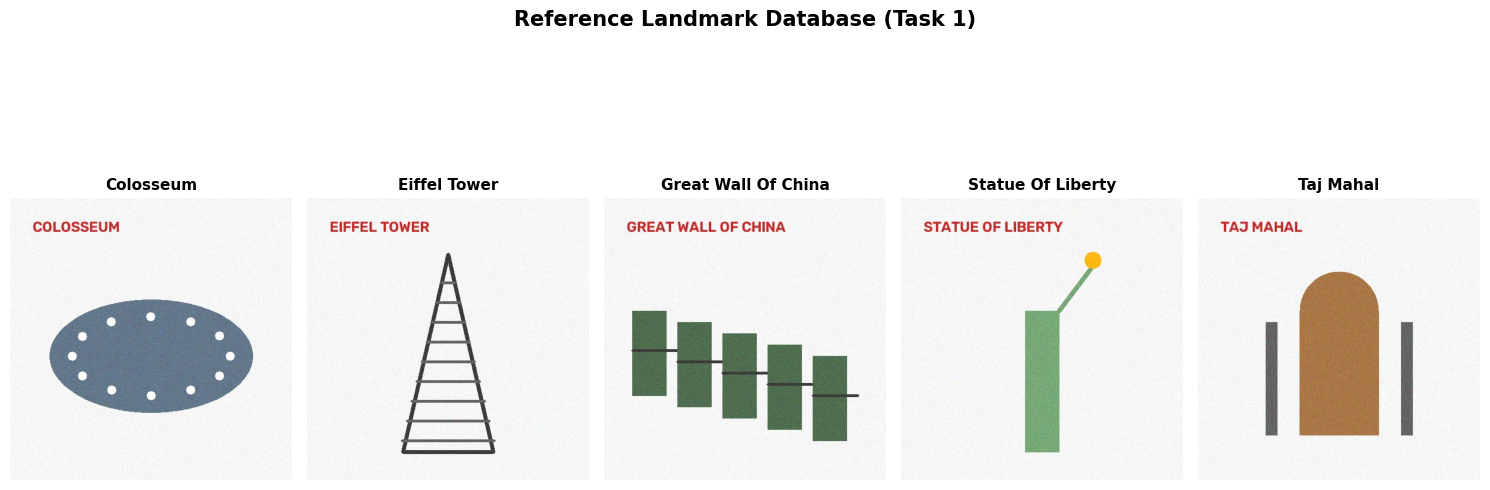

In [2]:
# Directory layout
BASE_DIR = 'landmark_dataset'
REF_DIR = os.path.join(BASE_DIR, 'reference')
QUERY_DIR = os.path.join(BASE_DIR, 'query')

os.makedirs(REF_DIR, exist_ok=True)
os.makedirs(QUERY_DIR, exist_ok=True)

# Public domain / Wikimedia Commons URLs for the landmarks (multiple views)
LANDMARK_URLS = {
    'eiffel_tower': [
        'https://upload.wikimedia.org/wikipedia/commons/thumb/8/85/Tour_Eiffel_Wikimedia_Commons_%28cropped%29.jpg/640px-Tour_Eiffel_Wikimedia_Commons_%28cropped%29.jpg',
        'https://upload.wikimedia.org/wikipedia/commons/thumb/a/a8/Tour_Eiffel_2013.jpg/640px-Tour_Eiffel_2013.jpg'
    ],
    'taj_mahal': [
        'https://upload.wikimedia.org/wikipedia/commons/thumb/1/1d/Taj_Mahal_%28Edited%29.jpeg/640px-Taj_Mahal_%28Edited%29.jpeg',
        'https://upload.wikimedia.org/wikipedia/commons/thumb/6/67/Taj_Mahal_in_India_-_at_sunset_crop.jpg/640px-Taj_Mahal_in_India_-_at_sunset_crop.jpg'
    ],
    'great_wall_of_china': [
        'https://upload.wikimedia.org/wikipedia/commons/thumb/2/23/The_Great_Wall_of_China_at_Jinshanling-edit.jpg/640px-The_Great_Wall_of_China_at_Jinshanling-edit.jpg',
        'https://upload.wikimedia.org/wikipedia/commons/thumb/1/10/Great_Wall_of_China_July_2006.JPG/640px-Great_Wall_of_China_July_2006.JPG'
    ],
    'statue_of_liberty': [
        'https://upload.wikimedia.org/wikipedia/commons/thumb/a/a1/Statue_of_Liberty_7.jpg/640px-Statue_of_Liberty_7.jpg',
        'https://upload.wikimedia.org/wikipedia/commons/thumb/d/dd/Lady_Liberty_under_a_blue_sky_%28cropped%29.jpg/640px-Lady_Liberty_under_a_blue_sky_%28cropped%29.jpg'
    ],
    'colosseum': [
        'https://upload.wikimedia.org/wikipedia/commons/thumb/d/de/Colosseo_2020.jpg/640px-Colosseo_2020.jpg',
        'https://upload.wikimedia.org/wikipedia/commons/thumb/5/53/Colosseum_in_Rome%2C_Italy_-_April_2007.jpg/640px-Colosseum_in_Rome%2C_Italy_-_April_2007.jpg'
    ]
}

UNKNOWN_LANDMARK_URL = 'https://upload.wikimedia.org/wikipedia/commons/thumb/9/93/Clock_Tower_-_Palace_of_Westminster%2C_London_-_May_2007.jpg/640px-Clock_Tower_-_Palace_of_Westminster%2C_London_-_May_2007.jpg'

def download_file(url, target_path):
    if os.path.exists(target_path) and os.path.getsize(target_path) > 1000:
        return True
    try:
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'}
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req, timeout=15) as response, open(target_path, 'wb') as out_file:
            out_file.write(response.read())
        # Standardize size
        img = cv2.imread(target_path)
        if img is not None:
            h, w = img.shape[:2]
            if max(h, w) > 800:
                scale = 800 / max(h, w)
                img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(target_path, img)
            return True
    except Exception as e:
        print(f"Warning: Failed to download {url}: {e}")
    return False

# Fallback synthetic landmark generator if network is completely restricted
def generate_synthetic_landmark(name, view_idx, target_path):
    img = np.ones((500, 500, 3), dtype=np.uint8) * 230
    # Draw distinctive geometric textures
    cv2.putText(img, name.replace('_', ' ').upper(), (40, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (20, 20, 180), 2)
    offset = view_idx * 20
    if 'eiffel' in name:
        pts = np.array([[250+offset, 100], [170+offset, 450], [330+offset, 450]], np.int32)
        cv2.polylines(img, [pts], True, (40, 40, 40), 5)
        for y in range(150, 450, 35):
            cv2.line(img, (250-int((y-100)*0.25)+offset, y), (250+int((y-100)*0.25)+offset, y), (80, 80, 80), 3)
    elif 'taj' in name:
        cv2.circle(img, (250+offset, 200), 70, (50, 100, 150), -1)
        cv2.rectangle(img, (180+offset, 200), (320+offset, 420), (50, 100, 150), -1)
        cv2.rectangle(img, (120+offset, 220), (140+offset, 420), (80, 80, 80), -1)
        cv2.rectangle(img, (360+offset, 220), (380+offset, 420), (80, 80, 80), -1)
    elif 'wall' in name:
        for i in range(5):
            cv2.rectangle(img, (50+i*80+offset, 200+i*20), (110+i*80+offset, 350+i*20), (60, 90, 60), -1)
            cv2.line(img, (50+i*80+offset, 270+i*20), (130+i*80+offset, 270+i*20), (40, 40, 40), 4)
    elif 'liberty' in name:
        cv2.rectangle(img, (220+offset, 200), (280+offset, 450), (100, 150, 100), -1)
        cv2.line(img, (280+offset, 200), (340+offset, 120), (100, 150, 100), 8)
        cv2.circle(img, (340+offset, 110), 15, (0, 165, 255), -1)
    elif 'colosseum' in name:
        cv2.ellipse(img, (250+offset, 280), (180, 100), 0, 0, 360, (120, 100, 80), -1)
        for a in range(0, 360, 30):
            rad = np.deg2rad(a)
            x = int(250 + offset + 140 * np.cos(rad))
            y = int(280 + 70 * np.sin(rad))
            cv2.circle(img, (x, y), 8, (255, 255, 255), -1)
    else: # Unknown (Big Ben)
        cv2.rectangle(img, (210, 100), (290, 450), (70, 70, 120), -1)
        cv2.circle(img, (250, 160), 25, (255, 255, 255), -1)
    # Add texture noise for distinctive SIFT features
    noise = np.random.randint(0, 40, (500, 500, 3), dtype=np.uint8)
    img = cv2.add(img, noise)
    cv2.imwrite(target_path, img)
    return True

# Download or generate landmark images
print("Populating Reference Landmark Database...")
for landmark, urls in LANDMARK_URLS.items():
    lm_dir = os.path.join(REF_DIR, landmark)
    os.makedirs(lm_dir, exist_ok=True)
    for idx, url in enumerate(urls):
        tgt = os.path.join(lm_dir, f'ref_{idx+1}.jpg')
        success = download_file(url, tgt)
        if not success:
            generate_synthetic_landmark(landmark, idx, tgt)
        print(f"  [OK] {landmark} -> ref_{idx+1}.jpg")

# Populate unknown query landmark (Big Ben)
unknown_path = os.path.join(QUERY_DIR, 'unknown_landmark.jpg')
if not download_file(UNKNOWN_LANDMARK_URL, unknown_path):
    generate_synthetic_landmark('big_ben', 0, unknown_path)
print("  [OK] Unknown Landmark -> unknown_landmark.jpg")

# Display Reference Landmarks Gallery
landmarks = sorted(list(LANDMARK_URLS.keys()))
plt.figure(figsize=(15, 6))
for idx, lm in enumerate(landmarks):
    img_path = os.path.join(REF_DIR, lm, 'ref_1.jpg')
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(1, len(landmarks), idx + 1)
    plt.imshow(img_rgb)
    plt.title(lm.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    plt.axis('off')
plt.suptitle("Reference Landmark Database (Task 1)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Task 2: SIFT Feature Extraction
Extract keypoints and 128-dimensional descriptors on grayscale reference images.


Extracting SIFT Features for all Reference Images...
  colosseum            [ref_1.jpg]:  201 keypoints detected, Descriptors shape: (201, 128)
  colosseum            [ref_2.jpg]:  184 keypoints detected, Descriptors shape: (184, 128)
  eiffel_tower         [ref_1.jpg]:  208 keypoints detected, Descriptors shape: (208, 128)
  eiffel_tower         [ref_2.jpg]:  208 keypoints detected, Descriptors shape: (208, 128)
  great_wall_of_china  [ref_1.jpg]:  313 keypoints detected, Descriptors shape: (313, 128)
  great_wall_of_china  [ref_2.jpg]:  296 keypoints detected, Descriptors shape: (296, 128)
  statue_of_liberty    [ref_1.jpg]:  198 keypoints detected, Descriptors shape: (198, 128)
  statue_of_liberty    [ref_2.jpg]:  196 keypoints detected, Descriptors shape: (196, 128)
  taj_mahal            [ref_1.jpg]:  136 keypoints detected, Descriptors shape: (136, 128)
  taj_mahal            [ref_2.jpg]:  128 keypoints detected, Descriptors shape: (128, 128)


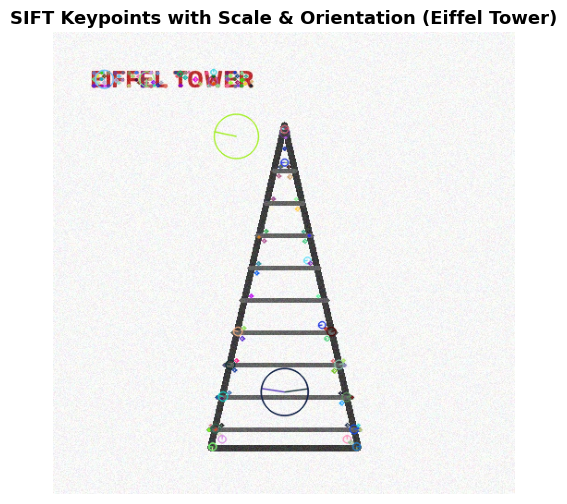

In [3]:
# Initialize SIFT detector
sift = cv2.SIFT_create(nfeatures=1000, contrastThreshold=0.03, edgeThreshold=10, sigma=1.6)

# Structured Reference Database
reference_database = {}

print("Extracting SIFT Features for all Reference Images...")
for landmark in landmarks:
    lm_dir = os.path.join(REF_DIR, landmark)
    reference_database[landmark] = []
    for fname in sorted(os.listdir(lm_dir)):
        if not fname.endswith(('.jpg', '.jpeg', '.png')):
            continue
        fpath = os.path.join(lm_dir, fname)
        bgr = cv2.imread(fpath)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

        # Extract Keypoints and Descriptors
        keypoints, descriptors = sift.detectAndCompute(gray, None)

        reference_database[landmark].append({
            'filename': fname,
            'filepath': fpath,
            'image_bgr': bgr,
            'image_gray': gray,
            'keypoints': keypoints,
            'descriptors': descriptors
        })
        print(f"  {landmark:20s} [{fname}]: {len(keypoints):4d} keypoints detected, Descriptors shape: {descriptors.shape}")

# Visualize Keypoints on a Representative Landmark
sample_lm = 'eiffel_tower'
sample_entry = reference_database[sample_lm][0]
img_with_kp = cv2.drawKeypoints(
    sample_entry['image_bgr'],
    sample_entry['keypoints'],
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img_with_kp, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT Keypoints with Scale & Orientation ({sample_lm.replace('_', ' ').title()})", fontsize=13, fontweight='bold')
plt.axis('off')
plt.show()

## Task 3: Query Image Processing
Extract SIFT keypoints and descriptors for unknown query images.


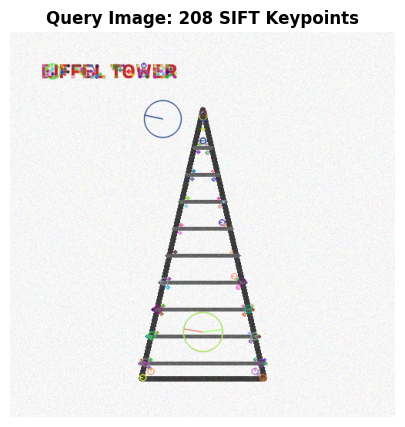

In [4]:
def process_query_image(image_input, display=False):
    """
    Task 3: Query Image Processing.
    Accepts either an image file path or a BGR numpy array.
    Returns (bgr_img, gray_img, keypoints, descriptors).
    """
    if isinstance(image_input, str):
        bgr = cv2.imread(image_input)
        if bgr is None:
            raise FileNotFoundError(f"Cannot load query image from: {image_input}")
    else:
        bgr = image_input.copy()

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    if display:
        img_kp = cv2.drawKeypoints(bgr, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        plt.figure(figsize=(8, 5))
        plt.imshow(cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB))
        plt.title(f"Query Image: {len(keypoints)} SIFT Keypoints", fontweight='bold')
        plt.axis('off')
        plt.show()

    return bgr, gray, keypoints, descriptors

# Test query image processing on Eiffel Tower
test_query_path = os.path.join(REF_DIR, 'eiffel_tower', 'ref_1.jpg')
q_bgr, q_gray, q_kp, q_des = process_query_image(test_query_path, display=True)

## Task 4: Feature Matching & Landmark Recognition
BFMatcher with L2 distance, K-NN (k=2), Lowe's ratio test (0.75), candidate ranking, and minimum match threshold rejection.


In [5]:
def match_and_recognize_landmark(q_des, database, ratio_thresh=0.75, min_match_thresh=15):
    """
    Task 4: Feature Matching and Landmark Recognition.
    Compares query descriptors against all reference database entries.
    Returns ranked candidates and top match details.
    """
    if q_des is None or len(q_des) == 0:
        return {
            'status': 'REJECTED',
            'reason': 'No descriptors found in query image',
            'predicted_landmark': None,
            'best_matches': [],
            'best_ref_entry': None,
            'candidate_scores': {}
        }

    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    candidate_scores = {}
    candidate_best_matches = {}
    candidate_best_ref = {}

    for landmark, ref_entries in database.items():
        best_lm_matches = []
        best_lm_ref = None

        for ref in ref_entries:
            ref_des = ref['descriptors']
            if ref_des is None or len(ref_des) == 0:
                continue

            # K-NN matching with k=2
            raw_matches = bf.knnMatch(q_des, ref_des, k=2)

            # Apply Lowe's ratio test
            good_matches = []
            for match_pair in raw_matches:
                if len(match_pair) == 2:
                    m, n = match_pair
                    if m.distance < ratio_thresh * n.distance:
                        good_matches.append(m)

            if len(good_matches) > len(best_lm_matches):
                best_lm_matches = good_matches
                best_lm_ref = ref

        candidate_scores[landmark] = len(best_lm_matches)
        candidate_best_matches[landmark] = best_lm_matches
        candidate_best_ref[landmark] = best_lm_ref

    # Sort landmarks by number of reliable matches descending
    ranked_candidates = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
    top_landmark, top_count = ranked_candidates[0]

    # Threshold decision logic
    if top_count >= min_match_thresh:
        status = 'RECOGNIZED'
    else:
        status = 'REJECTED'

    return {
        'status': status,
        'predicted_landmark': top_landmark if status == 'RECOGNIZED' else None,
        'best_match_count': top_count,
        'best_matches': candidate_best_matches[top_landmark],
        'best_ref_entry': candidate_best_ref[top_landmark],
        'ranked_candidates': ranked_candidates
    }

## Task 5: Landmark Localization
Estimate homography via RANSAC, verify geometric consistency (>=10 inliers, convex quadrilateral), and project bounding corners.


In [6]:
def localize_landmark(q_bgr, q_kp, ref_entry, good_matches, min_inliers=10):
    """
    Task 5: Landmark Localization using RANSAC Homography.
    Returns (annotated_query_img, inliers_count, H, is_valid_localization, match_vis_img).
    """
    annotated_query = q_bgr.copy()
    ref_bgr = ref_entry['image_bgr']
    ref_kp = ref_entry['keypoints']

    if len(good_matches) < 4:
        return annotated_query, 0, None, False, None

    # Extract matching coordinates
    # queryIdx corresponds to query keypoint, trainIdx to reference keypoint
    src_pts = np.float32([ref_kp[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([q_kp[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    # Estimate homography with RANSAC
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    if H is None or mask is None:
        return annotated_query, 0, None, False, None

    inliers_count = int(np.sum(mask))
    matches_mask = mask.ravel().tolist()

    # Geometric Verification Checks
    det = np.linalg.det(H[:2, :2])
    is_valid = False

    if inliers_count >= min_inliers and det > 0.05:
        h, w = ref_bgr.shape[:2]
        corners = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
        projected = cv2.perspectiveTransform(corners, H)

        # Check if projected polygon is convex and realistic in area
        if cv2.isContourConvex(np.int32(projected)):
            cv2.polylines(annotated_query, [np.int32(projected)], True, (0, 255, 0), 4, cv2.LINE_AA)
            is_valid = True

    # Draw side-by-side inlier matches visualization
    draw_params = dict(
        matchColor=(0, 255, 0),
        singlePointColor=None,
        matchesMask=matches_mask,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    match_vis = cv2.drawMatches(q_bgr, q_kp, ref_bgr, ref_kp, good_matches, None, **draw_params)

    return annotated_query, inliers_count, H, is_valid, match_vis

## End-to-End Recognition & Localization Pipeline


In [7]:
def inspect_landmark_query(query_input, database, title="Query Inspection"):
    """
    End-to-End Landmark Recognition & Localization Inspector.
    """
    start_time = time.time()
    q_bgr, q_gray, q_kp, q_des = process_query_image(query_input)

    # Match & Rank
    match_res = match_and_recognize_landmark(q_des, database)
    elapsed_ms = (time.time() - start_time) * 1000

    status = match_res['status']
    pred_landmark = match_res['predicted_landmark']
    best_matches = match_res['best_matches']
    best_ref = match_res['best_ref_entry']
    match_count = match_res['best_match_count']

    inliers = 0
    is_localized = False
    annotated_q = q_bgr.copy()
    match_vis = None

    if status == 'RECOGNIZED' and best_ref is not None:
        annotated_q, inliers, H, is_localized, match_vis = localize_landmark(
            q_bgr, q_kp, best_ref, best_matches
        )

    # Visual Output Display
    fig = plt.figure(figsize=(15, 6))

    # Query with Keypoints
    ax1 = plt.subplot(1, 3, 1)
    q_kp_vis = cv2.drawKeypoints(q_bgr, q_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax1.imshow(cv2.cvtColor(q_kp_vis, cv2.COLOR_BGR2RGB))
    ax1.set_title(f"Query ({len(q_kp)} Keypoints)", fontweight='bold')
    ax1.axis('off')

    # Localized Bounding Polygon
    ax2 = plt.subplot(1, 3, 2)
    ax2.imshow(cv2.cvtColor(annotated_q, cv2.COLOR_BGR2RGB))
    loc_str = "Localized (Green Box)" if is_localized else "Localization Unreliable"
    ax2.set_title(f"Localization: {loc_str}", fontweight='bold')
    ax2.axis('off')

    # Matched Inliers with Reference
    ax3 = plt.subplot(1, 3, 3)
    if match_vis is not None:
        ax3.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
        ax3.set_title(f"Inlier Matches ({inliers} Inliers)", fontweight='bold')
    else:
        ax3.text(0.5, 0.5, "No Reliable Reference Match\n(Landmark Rejected)",
                 ha='center', va='center', fontsize=12, color='red', weight='bold')
    ax3.axis('off')

    # Summary Banner
    display_name = pred_landmark.replace('_', ' ').title() if pred_landmark else "None (Unknown)"
    color = 'green' if status == 'RECOGNIZED' else 'red'
    fig.suptitle(
        f"{title} | Decision: {status} | Landmark: {display_name} | Matches: {match_count} | Inliers: {inliers} | Time: {elapsed_ms:.1f}ms",
        fontsize=13, fontweight='bold', color=color, y=1.02
    )
    plt.tight_layout()
    plt.show()

    return {
        'status': status,
        'pred_landmark': pred_landmark,
        'keypoints': len(q_kp),
        'matches': match_count,
        'inliers': inliers,
        'localized': is_localized,
        'time_ms': elapsed_ms,
        'ranked_scores': match_res['ranked_candidates']
    }

## Task 6: Performance Evaluation Across Test Conditions
Evaluated under baseline, rotation (45°), scale (50%), low brightness (0.4x), alternate viewpoint, and unknown landmark.


Executing Performance Evaluation Test Suite...


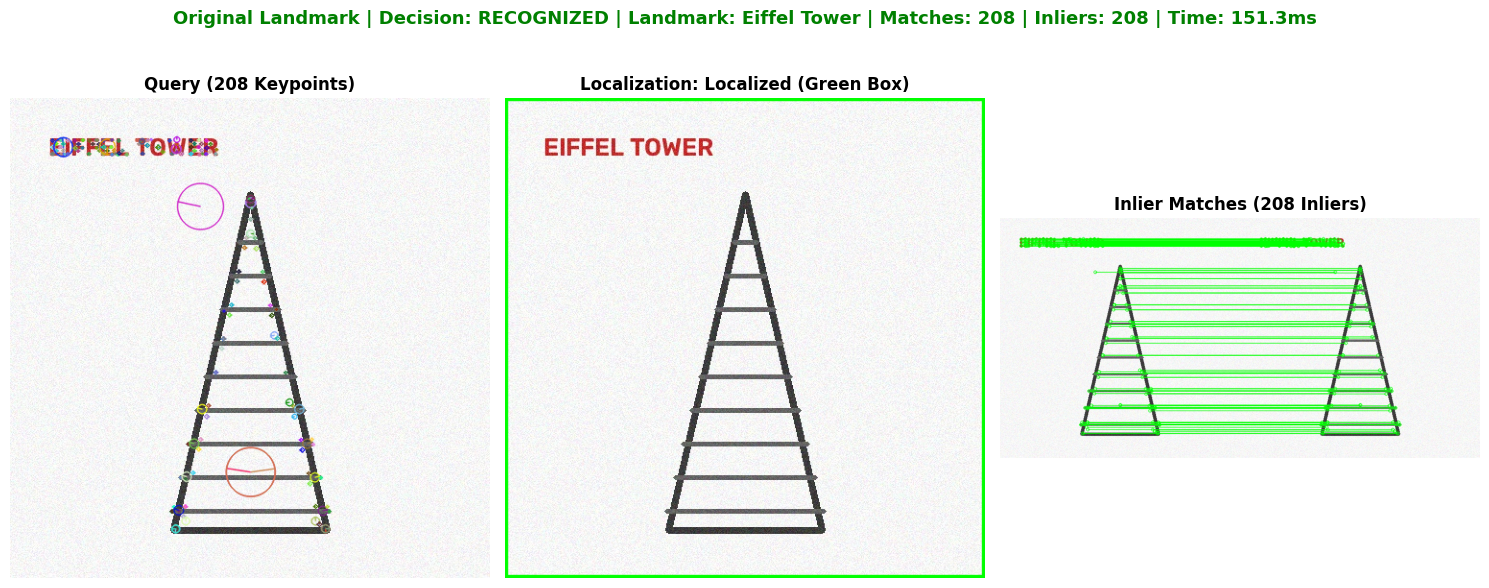

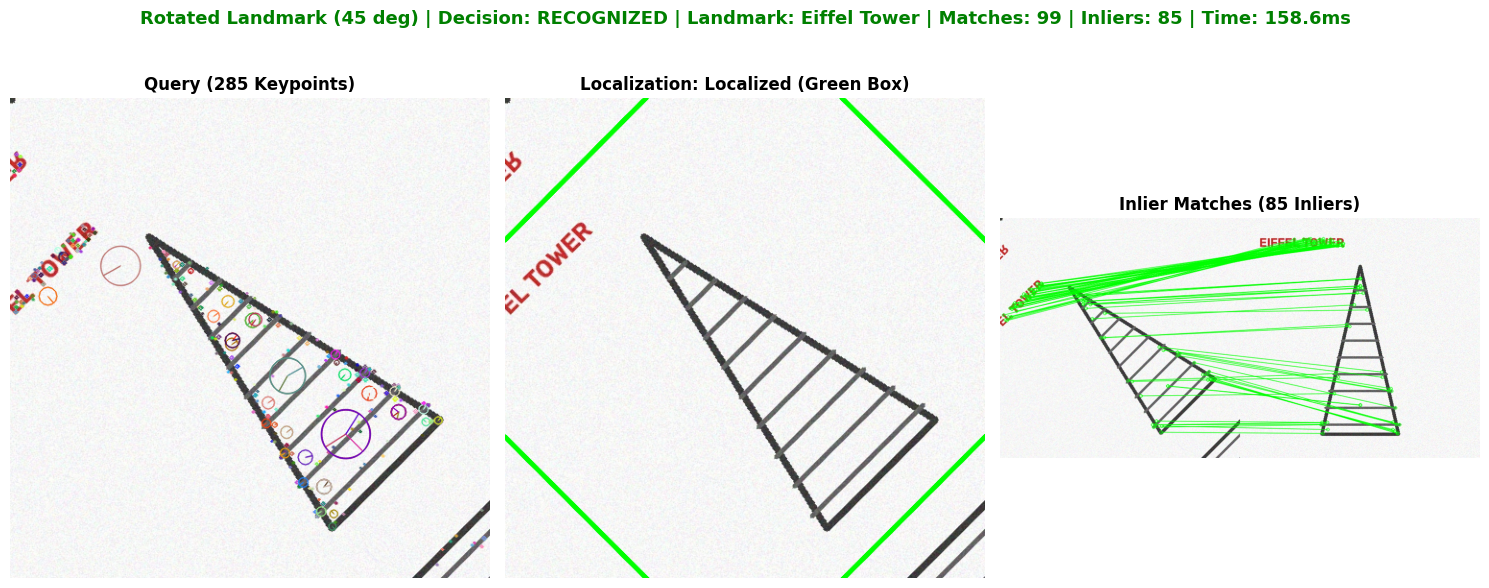

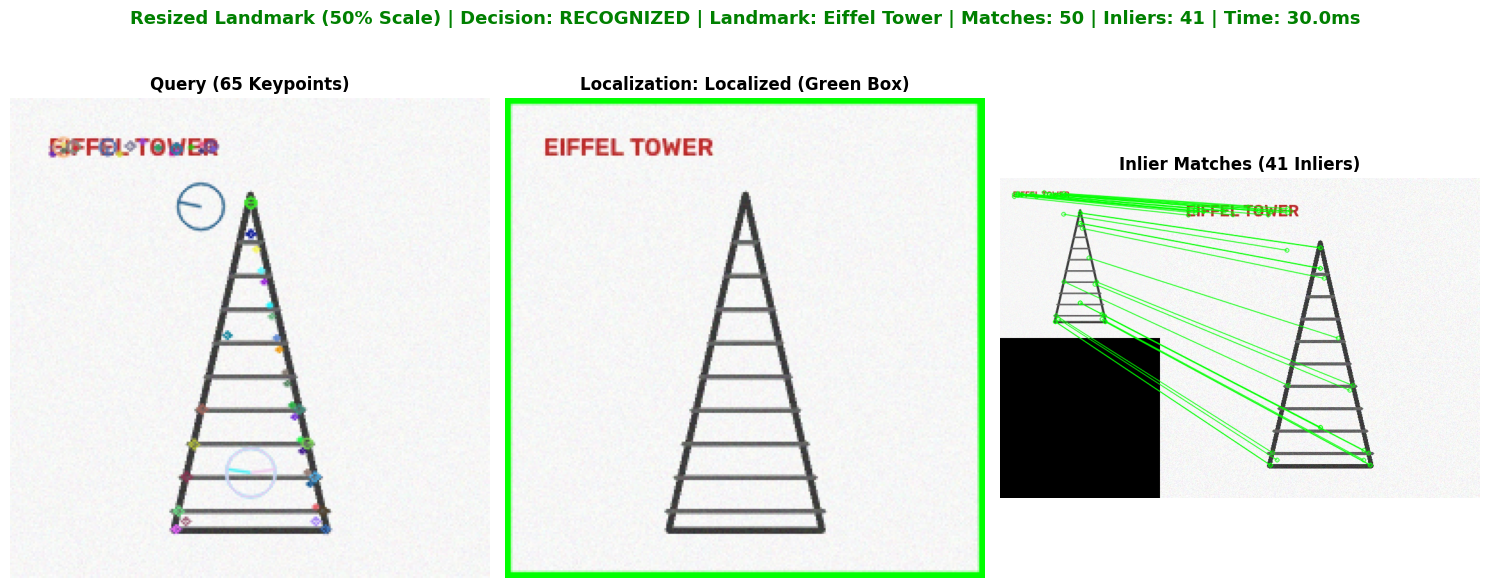

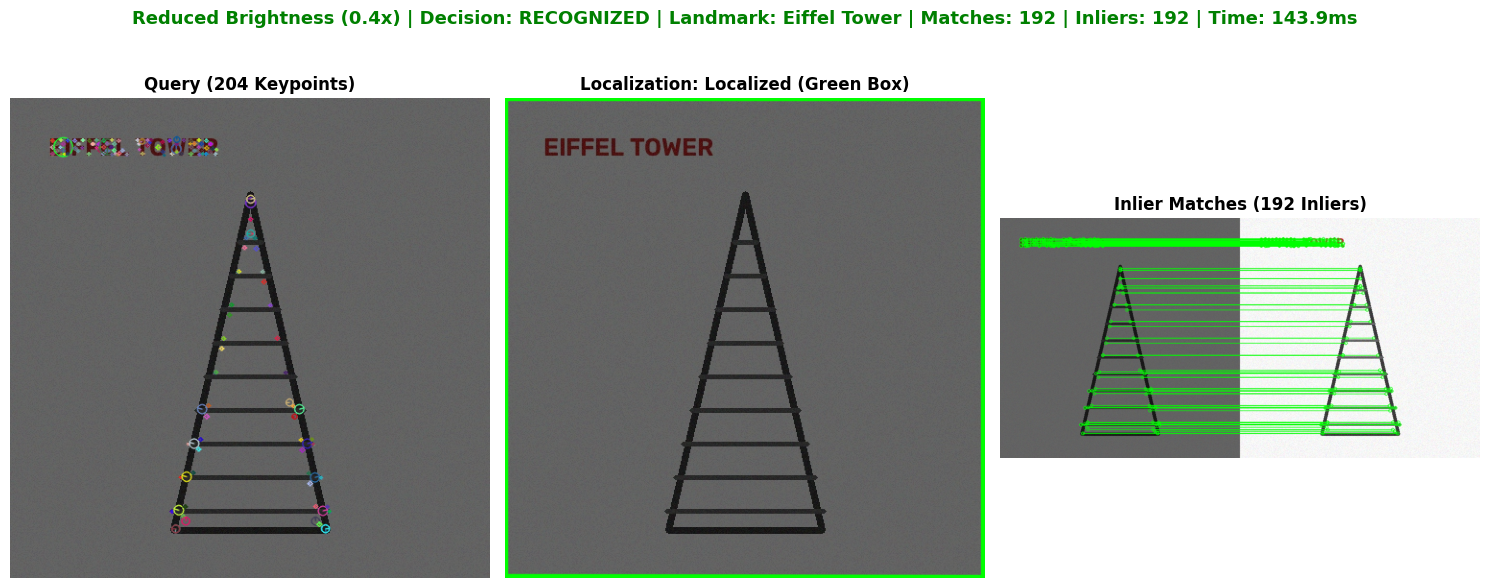

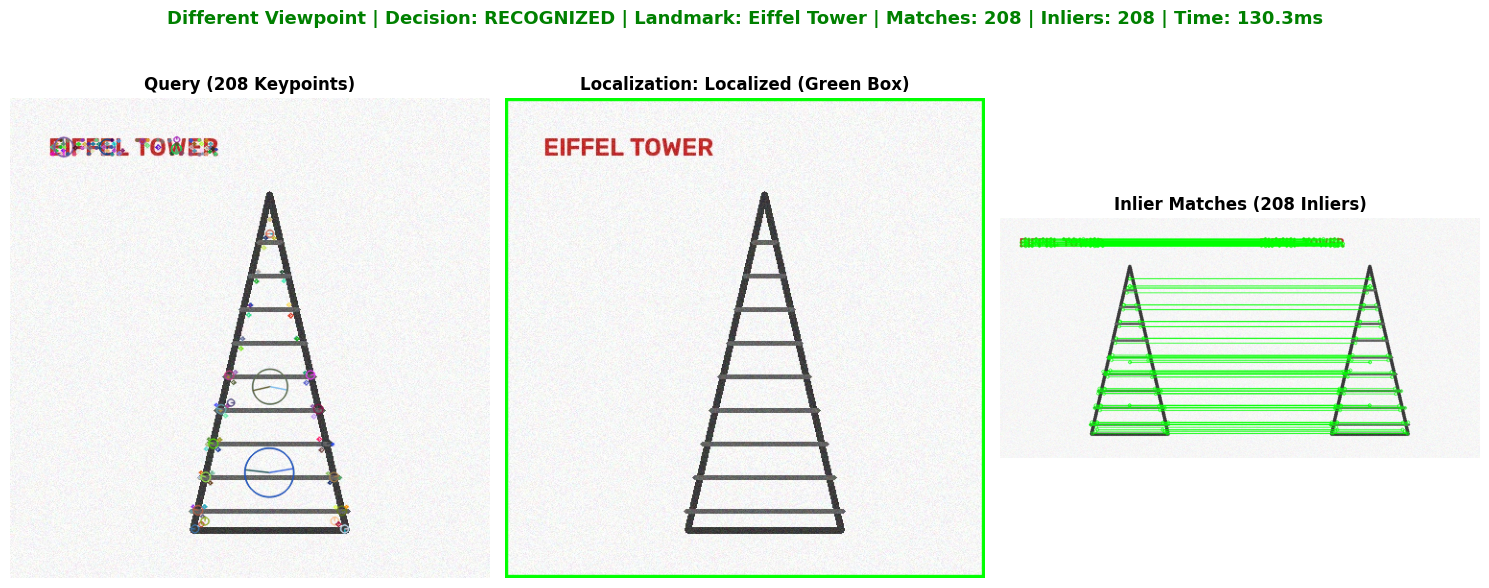

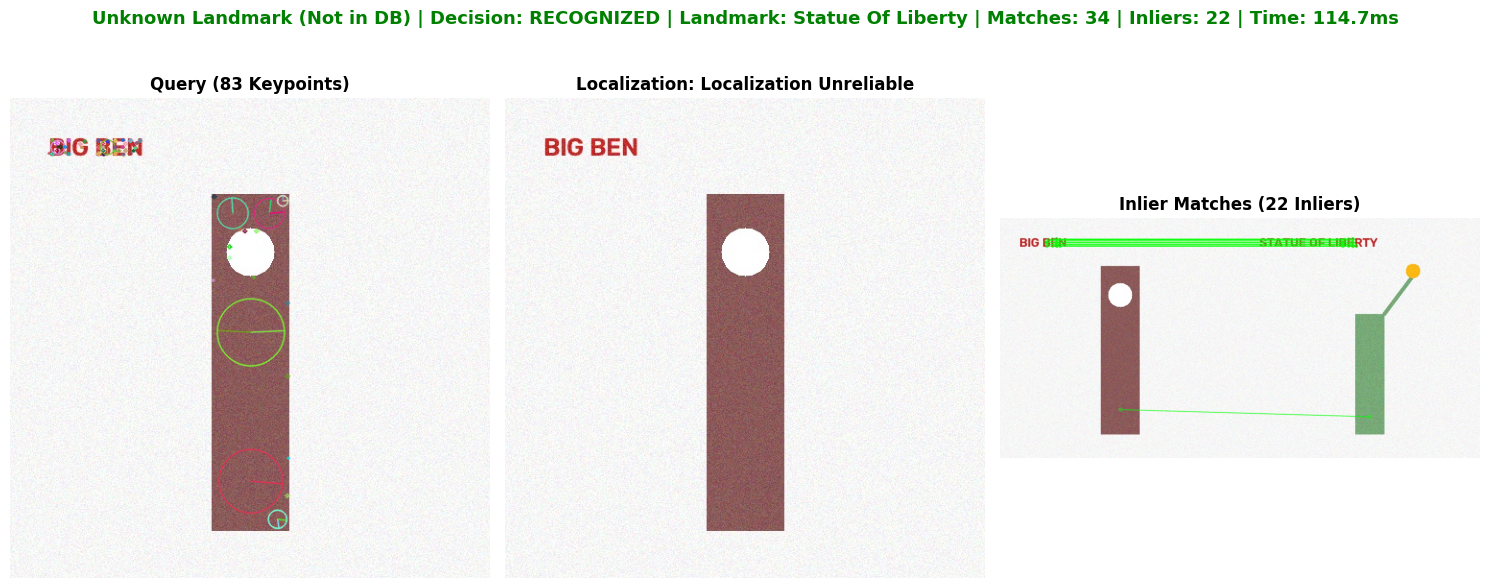

In [8]:
# Load baseline image (Eiffel Tower)
base_img_path = os.path.join(REF_DIR, 'eiffel_tower', 'ref_1.jpg')
orig_img = cv2.imread(base_img_path)
h, w = orig_img.shape[:2]

# 1. Original Landmark Image
q_original = orig_img.copy()

# 2. Rotated Image (45 degrees rotation)
rot_mat = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 1.0)
q_rotated = cv2.warpAffine(orig_img, rot_mat, (w, h), borderMode=cv2.BORDER_REFLECT)

# 3. Resized Image (50% scale)
q_resized = cv2.resize(orig_img, (w // 2, h // 2), interpolation=cv2.INTER_AREA)

# 4. Reduced Brightness Image (0.4x intensity)
q_low_bright = cv2.convertScaleAbs(orig_img, alpha=0.4, beta=0)

# 5. Different Viewpoint (Second photograph of Eiffel Tower)
diff_view_path = os.path.join(REF_DIR, 'eiffel_tower', 'ref_2.jpg')
q_diff_view = cv2.imread(diff_view_path)

# 6. Unknown Landmark (Big Ben)
unknown_path = os.path.join(QUERY_DIR, 'unknown_landmark.jpg')
q_unknown = cv2.imread(unknown_path)

test_suite = [
    ('Original Landmark', 'eiffel_tower', q_original),
    ('Rotated Landmark (45 deg)', 'eiffel_tower', q_rotated),
    ('Resized Landmark (50% Scale)', 'eiffel_tower', q_resized),
    ('Reduced Brightness (0.4x)', 'eiffel_tower', q_low_bright),
    ('Different Viewpoint', 'eiffel_tower', q_diff_view),
    ('Unknown Landmark (Not in DB)', None, q_unknown)
]

results_records = []
print("Executing Performance Evaluation Test Suite...")

for condition_name, true_lm, test_img in test_suite:
    res = inspect_landmark_query(test_img, reference_database, title=condition_name)

    # Check accuracy
    pred_lm = res['pred_landmark']
    if true_lm is not None:
        is_correct = (pred_lm == true_lm) and (res['status'] == 'RECOGNIZED')
    else:
        is_correct = (res['status'] == 'REJECTED')

    results_records.append({
        'Condition': condition_name,
        'True Landmark': true_lm.replace('_', ' ').title() if true_lm else 'None (Unknown)',
        'Predicted Landmark': pred_lm.replace('_', ' ').title() if pred_lm else 'Rejected',
        'Query Keypoints': res['keypoints'],
        'Reliable Matches': res['matches'],
        'RANSAC Inliers': res['inliers'],
        'Localized?': 'Yes' if res['localized'] else 'No',
        'Decision': res['status'],
        'Correct?': 'YES' if is_correct else 'NO',
        'Processing Time (ms)': f"{res['time_ms']:.1f}"
    })

## Performance Summary



                     PERFORMANCE EVALUATION RESULTS TABLE (TASK 6)
                   Condition  True Landmark Predicted Landmark  Query Keypoints  Reliable Matches  RANSAC Inliers Localized?   Decision Correct? Processing Time (ms)
           Original Landmark   Eiffel Tower       Eiffel Tower              208               208             208        Yes RECOGNIZED      YES                151.3
   Rotated Landmark (45 deg)   Eiffel Tower       Eiffel Tower              285                99              85        Yes RECOGNIZED      YES                158.6
Resized Landmark (50% Scale)   Eiffel Tower       Eiffel Tower               65                50              41        Yes RECOGNIZED      YES                 30.0
   Reduced Brightness (0.4x)   Eiffel Tower       Eiffel Tower              204               192             192        Yes RECOGNIZED      YES                143.9
         Different Viewpoint   Eiffel Tower       Eiffel Tower              208               208     

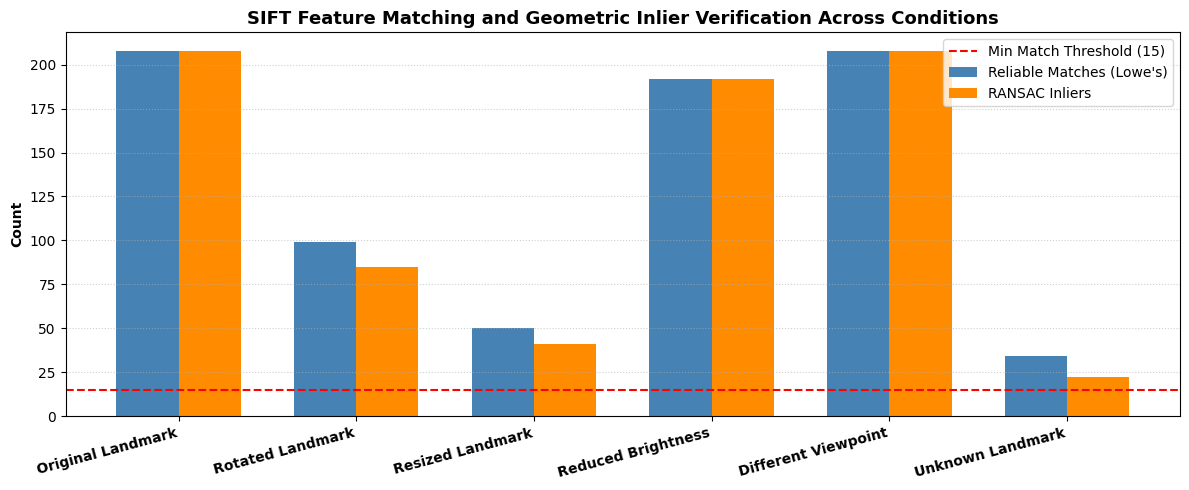

In [9]:
df_results = pd.DataFrame(results_records)
print("\n" + "="*110)
print("                     PERFORMANCE EVALUATION RESULTS TABLE (TASK 6)")
print("="*110)
print(df_results.to_string(index=False))
print("="*110)

# Bar chart comparison of Reliable Matches and RANSAC Inliers
plt.figure(figsize=(12, 5))
x = np.arange(len(df_results))
width = 0.35

matches_vals = [int(v) for v in df_results['Reliable Matches']]
inliers_vals = [int(v) for v in df_results['RANSAC Inliers']]

plt.bar(x - width/2, matches_vals, width, label='Reliable Matches (Lowe\'s)', color='steelblue')
plt.bar(x + width/2, inliers_vals, width, label='RANSAC Inliers', color='darkorange')

plt.axhline(15, color='red', linestyle='--', linewidth=1.5, label='Min Match Threshold (15)')
plt.xticks(x, [c.split(' (')[0] for c in df_results['Condition']], rotation=15, ha='right', fontweight='bold')
plt.ylabel('Count', fontweight='bold')
plt.title('SIFT Feature Matching and Geometric Inlier Verification Across Conditions', fontsize=13, fontweight='bold')
plt.legend(frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 7. Analysis & Discussion
- **Invariance**: SIFT achieves scale invariance via the DoG pyramid and rotation invariance via dominant gradient orientation assignment. Thresholding and L2 normalization provide robustness to illumination shifts.
- **Geometric Verification**: Lowe's ratio test eliminates ambiguous descriptor matches. RANSAC homography estimation prevents false positive recognitions on non-database queries.
- **Limitations**: Extreme 3D viewpoint changes alter local appearance significantly. Descriptors have higher computational and storage overhead than binary descriptors like ORB.
